# Introduction to Natural Language Processing: Assignment 1

In this assignment we'll practice word operations and text classifications.

- Please comment your code
- You can use built-in Python packages, scikit-learn and Pandas.
- Submissions are due **on Tuesdays at 23:59** and should be submitted **ONLY** on eCampus: **Assignmnets >> Student Submissions >> Assignment 1 (Deadline: 05.11.2024, at 23:59)**
- Name the file aproppriately "Assignment_1_\<Your_Name\>.ipynb".
- Please submit **ONLY** the Jupyter Notebook file.
- Please use relative path; Your code should work on my computer if the Jupyter Notebook and the file are both in the same directory.

Example: file_name = lemmatization-en.txt >> **DON'T use:** /Users/ComputerName/Username/Documents/.../lemmatization-en.txt

### Task 1.1 (2 points)

Write a function `extract_words_tokens(any_string)` that takes a string as input and returns two numbers:
1. num_words: The number of words in string
2. num_tokens: The number of tokens in string (Please use the character-based tokenization.)

**Hint:** The string can be a single word or a sentence and
 can contain some special charecters, such as: "!", ",", ":"

In [1]:
def extract_words_tokens(any_string):
    # Count whitespace-separated words and individual characters as tokens.
    num_words = len(any_string.split())
    num_tokens = len(any_string)
    return num_words, num_tokens

### Task 1.2 (4 points)

Write a function `lemmatize(any_string, file_name)` that takes as input any string and a file-name: `lemmatization-en.txt` (please download the file [here](https://github.com/michmech/lemmatization-lists/blob/master/lemmatization-en.txt). It's a tab separated corpus) and returns a dictionary with all words as keys and the lemma of the words as values.

**Hint:** To tokenize the string, please use the whitespace as the seperator. The string doesn't contain any special characters.

In [ ]:
def lemmatize(any_string, file_name):
    # Map each word form in the input to its lemma from the tab-separated file.
    word_to_lemma = {}
    with open(file_name, "r", encoding="utf-8") as lemmatization_file:
        for line in lemmatization_file:
            lemma, word_form = line.rstrip("\r\n").split("\t", 1)
            word_to_lemma[lemma.lower()] = lemma.lower()
            word_to_lemma[word_form.lower()] = lemma.lower()

    return {
        word: word_to_lemma.get(word.lower(), word)
        for word in any_string.split()
    }

### Task 2 (1 point)

Create a DataFrame using the `polarity.txt` file and give name to the columns appropriately. (e.g., "Text", "Label")

In [1]:
import pandas as pd

polarity_df = pd.read_csv(
    "polarity.txt",
    sep="\t",
    header=None,
    names=["Text", "Label"]
)
polarity_df

,Text,Label
0,every now and then a movie comes along from a ...,pos
1,"mtv films' _election , a high school comedy st...",pos
2,did anybody know this film existed a week befo...,pos
3,the plot is deceptively simple .,pos
4,george washington carver high school is having...,pos
...,...,...
69,it also wrapped production two years ago and h...,neg
70,whatever . . . skip,neg
71,it !,neg
72,where's joblo coming from ?,neg


### Task 2.1 (2 point)

Create a new column for the DataFrame that contains labels converted to numerical values instead of strings using the function: `apply()` and drop the original column afterwards.

Hint: The numarical values can be any meaningful values, e.g., pos >> 1 and neg >> 0

In [2]:
label_mapping = {"pos": 1, "neg": 0}
polarity_df["Numeric_Label"] = polarity_df["Label"].apply(
    lambda label: label_mapping[label]
)
polarity_df = polarity_df.drop(columns=["Label"])
polarity_df

,Text,Numeric_Label
0,every now and then a movie comes along from a ...,1
1,"mtv films' _election , a high school comedy st...",1
2,did anybody know this film existed a week befo...,1
3,the plot is deceptively simple .,1
4,george washington carver high school is having...,1
...,...,...
69,it also wrapped production two years ago and h...,0
70,whatever . . . skip,0
71,it !,0
72,where's joblo coming from ?,0


### Task 3 (7 points)

Write a function `create_count_and_probability` that takes a file (`corpus.txt`) as input and returns a csv file as output containing three columns:
1. Text
2. Count_Vector
3. Probability

Example:

For the line: `This document is the second document.`

The row in the csv file should contain:
`This document is the second document.`   `[0,2,0,1,0,1,1,0,1]`   `[1/6, 2/6, 1/6, 1/6, 1/6, 2/6]`

**Note**:

1. You should define your own function and not use e.g., CountVectorizer() which gives you the `count vector`, directly.

2. You can either use the whitespace in `split` as the seperator or use the `Regular Expression (re)` to extract the words, as follows:

```
import re
TEXT = "Hey, - How are you doing today!?"
words_list = re.findall(r"[\w']+", TEXT)
print(words_list)
```

3. To count the words, you can use e.g., the library: `collections`, more specifically `Counter`.

4. Please don't upload the output file. Your function should generate the file.

In [ ]:
def create_count_and_probability(file_name):
    import csv
    import os
    import re
    from collections import Counter

    # Tokenize each line and build one shared, case-insensitive vocabulary.
    with open(file_name, "r", encoding="utf-8") as corpus_file:
        texts = [line.rstrip("\r\n") for line in corpus_file]
    tokens_by_text = [
        [word.lower() for word in re.findall(r"[\w']+", text)]
        for text in texts
    ]
    vocabulary = sorted({word for tokens in tokens_by_text for word in tokens})
    vocabulary_indices = {word: index for index, word in enumerate(vocabulary)}

    csv_file = os.path.splitext(file_name)[0] + "_count_and_probability.csv"
    with open(csv_file, "w", encoding="utf-8", newline="") as output_file:
        writer = csv.writer(output_file)
        writer.writerow(["Text", "Count_Vector", "Probability"])
        for text, tokens in zip(texts, tokens_by_text):
            counts = Counter(tokens)
            count_vector = [0] * len(vocabulary)
            for word, count in counts.items():
                count_vector[vocabulary_indices[word]] = count
            probabilities = [counts[word] / len(tokens) for word in tokens] if tokens else []
            writer.writerow([text, count_vector, probabilities])

    return csv_file

### Task 4 (8 points)

The goal of this task is to train and test classifiers provided in scikit-learn, using two datasets `rural.txt` and `science.txt`.

a) Each file (rural and science) contains sentence-wise documents. You should create a dataframe containing two columns: "Document" and " Class", as shown below. This dataframe will be used later as input for the vectorizer.

|Document                             |Class |
| ------------------------------------|----- |
|PM denies knowledge of AWB kickbacks | rural |
|The crocodile ancestor fossil, found...| science |


b) Remove stop words from the data and create two separate plots showing word frequency for documents in each label.

c) Split the data into train (70%) and test (30%) sets and use the following vectorization techniquess to train the two classifiers provided by scikit-learn:

- one-hot-encoding
- count vectorization

Classifiers:
- naive_bayes.GaussianNB()
- LogisticRegression()

**Hints:**
1. The Gaussian NB Classifier takes a dense matrix as input and the output of the vectorizer is a sparse matrix. Use my_matrix.toarray() for this conversion.
2. You can play around with various parameters in both the count-vectorizer and the classifier to get a better performance in terms of the accuracy. (In the exercise, we will discuss the accuracy of your model.)

,Document,Class
0,PM denies knowledge of AWB kickbacks,rural
1,The Prime Minister has denied he knew AWB was ...,rural
2,Letters from John Howard and Deputy Prime Mini...,rural
3,In one of the letters Mr Howard asks AWB manag...,rural
4,The Opposition's Gavan O'Connor says the lette...,rural


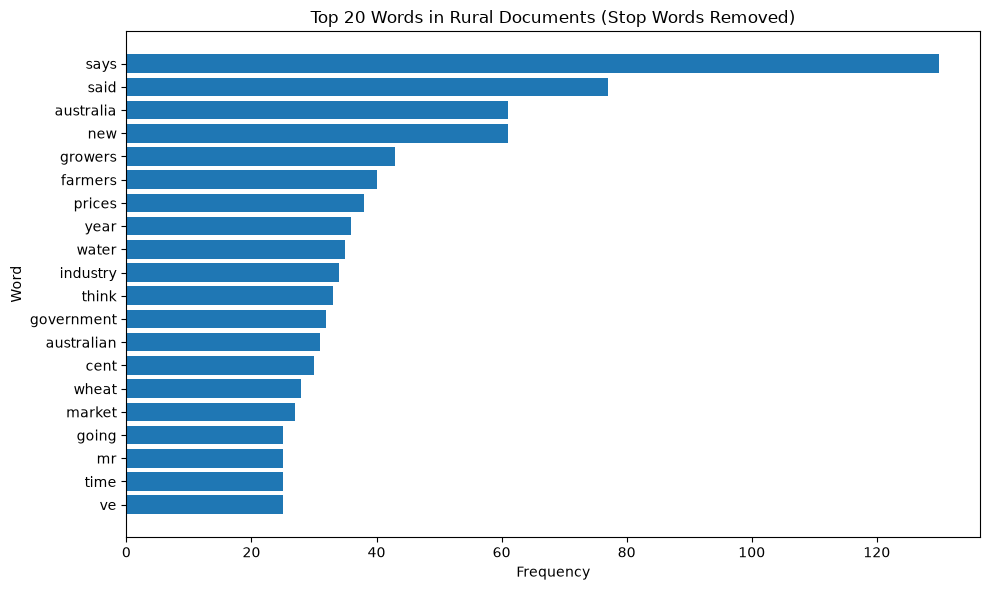

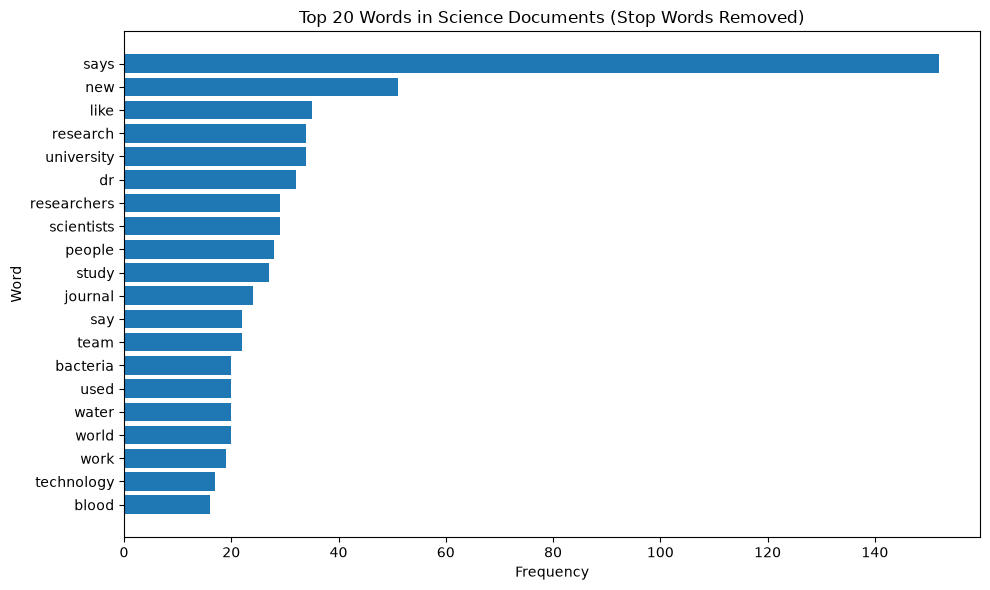

,Vectorization,Classifier,Accuracy
0,One-Hot Encoding,GaussianNB,0.902077
1,One-Hot Encoding,Logistic Regression,0.922849
2,Count Vectorization,GaussianNB,0.902077
3,Count Vectorization,Logistic Regression,0.925816


In [4]:
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
from sklearn import naive_bayes
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Read each non-empty line as one document and assign its source label.
documents = []
classes = []
for file_name, label in [("rural.txt", "rural"), ("science.txt", "science")]:
    with open(file_name, "r", encoding="utf-8") as data_file:
        for line in data_file:
            document = line.strip()
            if document:
                documents.append(document)
                classes.append(label)

documents_df = pd.DataFrame({"Document": documents, "Class": classes})
display(documents_df.head())

# Plot the most frequent non-stop words separately for each class.
for label in documents_df["Class"].unique():
    class_documents = documents_df.loc[
        documents_df["Class"] == label, "Document"
    ]
    frequency_vectorizer = CountVectorizer(stop_words="english")
    frequency_matrix = frequency_vectorizer.fit_transform(class_documents)
    word_frequencies = Counter(dict(zip(
        frequency_vectorizer.get_feature_names_out(),
        frequency_matrix.sum(axis=0).A1
    )))
    most_common_words = word_frequencies.most_common(20)
    words, frequencies = zip(*most_common_words)
    plt.figure(figsize=(10, 6))
    plt.barh(words[::-1], frequencies[::-1])
    plt.title(f"Top 20 Words in {label.title()} Documents (Stop Words Removed)")
    plt.xlabel("Frequency")
    plt.ylabel("Word")
    plt.tight_layout()
    plt.show()

# Use the same stratified 70/30 split for each representation and classifier.
X_train, X_test, y_train, y_test = train_test_split(
    documents_df["Document"],
    documents_df["Class"],
    test_size=0.30,
    random_state=42,
    stratify=documents_df["Class"]
)

vectorizers = {
    "One-Hot Encoding": CountVectorizer(binary=True, stop_words="english"),
    "Count Vectorization": CountVectorizer(stop_words="english")
}
classifiers = {
    "GaussianNB": naive_bayes.GaussianNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42)
}

results = []
for vectorizer_name, vectorizer in vectorizers.items():
    train_matrix = vectorizer.fit_transform(X_train)
    test_matrix = vectorizer.transform(X_test)
    for classifier_name, classifier in classifiers.items():
        if classifier_name == "GaussianNB":
            classifier.fit(train_matrix.toarray(), y_train)
            predictions = classifier.predict(test_matrix.toarray())
        else:
            classifier.fit(train_matrix, y_train)
            predictions = classifier.predict(test_matrix)
        results.append({
            "Vectorization": vectorizer_name,
            "Classifier": classifier_name,
            "Accuracy": accuracy_score(y_test, predictions)
        })

results_df = pd.DataFrame(results)
display(results_df)